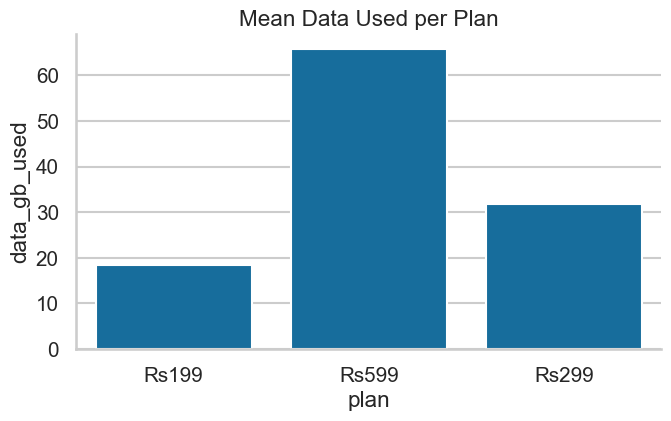

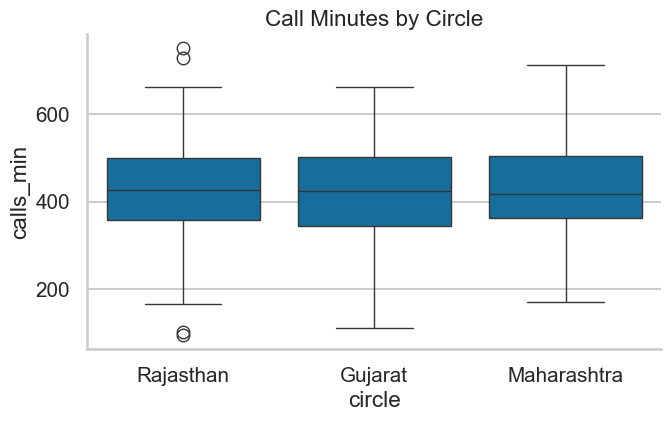

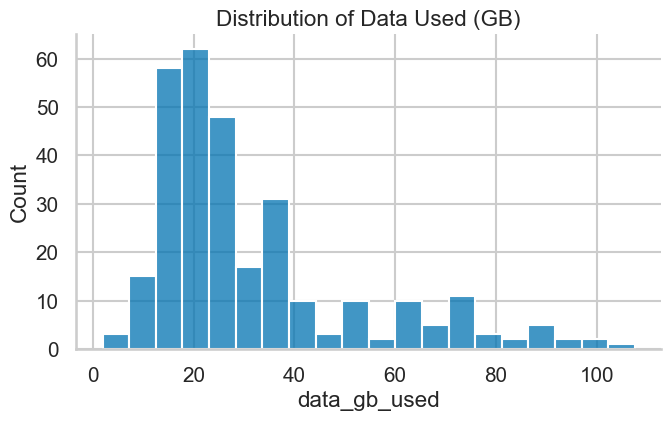

In [2]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from recharge_theme import apply_corporate_theme, export_chart

apply_corporate_theme()
df = pd.read_csv('recharge_usage.csv')

fig_bar, ax_bar = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=df, x='plan', y='data_gb_used', errorbar=None, ax=ax_bar)
ax_bar.set_title('Mean Data Used per Plan')
plt.tight_layout()

fig_box, ax_box = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df, x='circle', y='calls_min', ax=ax_box)
ax_box.set_title('Call Minutes by Circle')
plt.tight_layout()

fig_hist, ax_hist = plt.subplots(figsize=(7, 4.5))
sns.histplot(data=df, x='data_gb_used', bins=20, ax=ax_hist)
ax_hist.set_title('Distribution of Data Used (GB)')
plt.tight_layout()

In [3]:
for dpi in [100, 300, 600]:
    fname = f'bar_{dpi}.png'
    fig_bar.savefig(fname, dpi=dpi, bbox_inches='tight')
    size_kb = os.path.getsize(fname) / 1024
    width_px = plt.imread(fname).shape[1]
    print(f"{fname}: {size_kb:.1f} KB, width = {width_px} px")

bar_100.png: 18.0 KB, width = 671 px
bar_300.png: 70.6 KB, width = 2016 px
bar_600.png: 161.6 KB, width = 4032 px


In [4]:
plt.rcParams['svg.fonttype'] = 'none'

fig_hist.savefig('recharge_hist.svg', bbox_inches='tight')
fig_box.savefig('recharge_box.pdf', bbox_inches='tight')
print("Saved recharge_hist.svg and recharge_box.pdf")

Saved recharge_hist.svg and recharge_box.pdf


In [5]:
charts = [
    (fig_bar, 'mean_data_by_plan'),
    (fig_box, 'calls_by_circle'),
    (fig_hist, 'data_distribution')
]

summary_rows = []
for fig, name in charts:
    png_path, svg_path = export_chart(fig, name)
    for path, fmt in [(png_path, 'PNG'), (svg_path, 'SVG')]:
        summary_rows.append({
            'file': os.path.basename(path),
            'format': fmt,
            'size_kb': round(os.path.getsize(path) / 1024, 2)
        })

summary_df = pd.DataFrame(summary_rows)
print(summary_df)
summary_df.to_csv('export_summary.csv', index=False)

plt.show()

                    file format  size_kb
0  mean_data_by_plan.png    PNG    70.60
1  mean_data_by_plan.svg    SVG     8.08
2    calls_by_circle.png    PNG    68.30
3    calls_by_circle.svg    SVG     9.67
4  data_distribution.png    PNG    71.31
5  data_distribution.svg    SVG    15.07
